# 03 - The smooth-joint contact law

The foliation plane is made of **smooth-joint** contacts. Each contact is a small disc of area `A` that carries a normal
force `Fn` and a shear force `Fs`. Below is the law in simplified Python (compression positive). The aim is to show the
logic, not to replace the PFC implementation.

1. Normal force changes with the normal displacement increment: `Fn = Fn0 + kn A d_dn`.
2. The trial shear force changes with the shear increment: `Fs* = Fs0 - ks A d_ds`.
3. **Bonded**: the contact breaks in shear if `|Fs*| >= (c + sn tan(phi)) A`, with `sn = Fn/A`. It breaks in tension if `-sn > sj_ten`.
4. **After the break**: the shear force is limited by friction, `|Fs| <= mu Fn`, and tension is not carried.

Only the shear force has an asterisk because it is checked against a limit and may be reduced. The normal force is
already final, and it is only corrected afterwards by dilation (zero here, `sj_da = 0`).

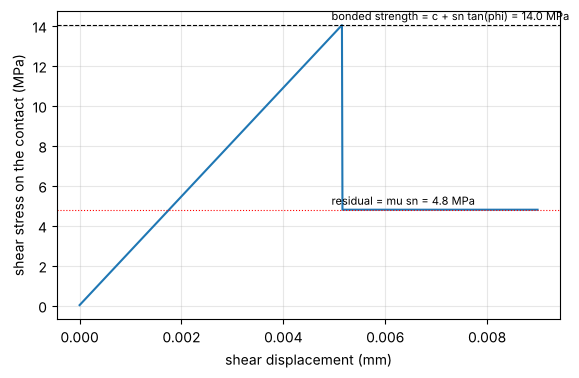

In [1]:
import numpy as np, matplotlib.pyplot as plt

def run(sn_const, c, phi_deg, mu, sj_ten, ks=2.72e12, A=1.0, ds=1e-8, n=900):
    """Constant normal stress (Pa), then imposed shear displacement. Returns shear stress history."""
    t = np.tan(np.radians(phi_deg))
    Fs, bonded, hist = 0.0, True, []
    Fn = sn_const*A
    for _ in range(n):
        Fs_trial = Fs + ks*A*ds                        # shear trial force
        if bonded:
            if -Fn/A > sj_ten:                          # tension break
                bonded = False
            elif abs(Fs_trial) >= (c + Fn/A*t)*A:        # shear break
                bonded = False
        if bonded:
            Fs = Fs_trial
        else:
            Fs = min(abs(Fs_trial), mu*max(Fn, 0.0))      # frictional limit
        hist.append(Fs/A)
    return np.array(hist)

sn, c, phi, mu = 10e6, 10e6, 22.0, 0.48
h = run(sn, c, phi, mu, 5e6)
peak = (c + sn*np.tan(np.radians(phi)))/1e6
res = mu*sn/1e6
x = np.arange(len(h))*1e-8*1e3
plt.figure(figsize=(6.5, 4)); plt.plot(x, h/1e6)
plt.axhline(peak, ls="--", c="k", lw=.8); plt.axhline(res, ls=":", c="r", lw=.8)
plt.text(x[-1]*.55, peak+.25, f"bonded strength = c + sn tan(phi) = {peak:.1f} MPa", fontsize=8)
plt.text(x[-1]*.55, res+.25, f"residual = mu sn = {res:.1f} MPa", fontsize=8)
plt.xlabel("shear displacement (mm)"); plt.ylabel("shear stress on the contact (MPa)"); plt.grid(alpha=.3); plt.show()

The curve rises elastically (slope = `ks`), the bond breaks at the Coulomb strength, and the contact then keeps
only the friction `mu sn`. The drop from the peak to the residual is the loss of cohesion.

## Does tension break the contact?

If the normal stress is tensile and larger than `sj_ten`, yes. Test it: with the same shear loading but a tensile normal
stress of 6 MPa and `sj_ten = 5 MPa`, the contact breaks before any shear.

In [2]:
h2 = run(-6e6, c, phi, mu, 5e6)
print("shear stress after loading, tension 6 MPa > sj_ten 5 MPa:", round(h2[-1]/1e6, 3), "MPa (no shear carried)")
h3 = run(-4e6, c, phi, mu, 5e6)
print("shear stress after loading, tension 4 MPa < sj_ten 5 MPa:", round(h3.max()/1e6, 3), "MPa (bond holds up to c - 4 tan(phi))")

shear stress after loading, tension 6 MPa > sj_ten 5 MPa: 0.0 MPa (no shear carried)
shear stress after loading, tension 4 MPa < sj_ten 5 MPa: 8.378 MPa (bond holds up to c - 4 tan(phi))


## Parameters in this repository

| Parameter | Meaning | Source |
| --- | --- | --- |
| `sj_kn`, `sj_ks` | stiffness of the plane contacts | same as the matrix (`p_fjkn`, `p_fjks`) |
| `sj_coh`, `sj_fa` | cohesion and friction angle of the bond | params file of the specimen |
| `sj_fric` | friction after the bond breaks | `p_sjfric` in Main |
| `sj_ten` | tensile strength of the bond | `p_sjten`, **no test data** |
| `sj_da` | dilation angle | zero |